In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from quantile_forest import RandomForestQuantileRegressor

1. Validate on all variables on both ships on model with all parameters
2. Validate on selected variables on both ships no model with only relevant parameters

In [2]:
X_train = np.load('../../output/data_eagles_vezhen/qrf/X_train2.npy')
y_train = np.load('../../output/data_eagles_vezhen/qrf/y_train2.npy')
X_test = np.load('../../output/data_eagles_vezhen/qrf/X_test2.npy')
y_test = np.load('../../output/data_eagles_vezhen/qrf/y_test2.npy')
X_val = np.load('../../output/data_eagles_vezhen/qrf/X_val2.npy')
y_val = np.load('../../output/data_eagles_vezhen/qrf/y_val2.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))


# Base model with all features

In [3]:
with open('../../output/models/qrf/hyperparam-fourth.pkl', 'rb+') as f:
    hyperparam_res = pickle.load(f)

# hyperparam_res

In [4]:
import pandas as pd
df_hyper = pd.DataFrame(hyperparam_res).melt()
df_hyper.columns = ['max_samples_leaf', 'max_features', 'max_samples', 'max_depth', 'value']
df_hyper['loss_low'] = df_hyper['value'].apply(lambda x: x[0])
df_hyper['loss_high'] = df_hyper['value'].apply(lambda x: x[1])
df_hyper.drop(columns=['value'], inplace=True)

In [5]:
df_hyper.groupby('max_samples_leaf')\
    [['loss_low', 'loss_high']]\
    .agg(['mean', 'std'])

loss_low           loss_high          
                      mean       std      mean       std
max_samples_leaf                                        
3                 0.006785  0.000205  0.007209  0.000219
5                 0.006771  0.000195  0.007167  0.000229

In [6]:
df_hyper.groupby('max_samples')\
    [['loss_low', 'loss_high']]\
    .agg(['mean', 'std'])

loss_low           loss_high          
                 mean       std      mean       std
max_samples                                        
0.50         0.006795  0.000221  0.007205  0.000260
0.75         0.006776  0.000217  0.007185  0.000220
1.00         0.006763  0.000167  0.007175  0.000202

In [7]:
df_hyper.groupby('max_features')\
    [['loss_low', 'loss_high']]\
    .agg(['mean', 'std'])

loss_low           loss_high          
                  mean       std      mean       std
max_features                                        
0.75          0.006720  0.000125  0.007104  0.000159
sqrt          0.006836  0.000240  0.007271  0.000248

In [8]:
df_hyper.groupby('max_depth', dropna=False)\
    [['loss_low', 'loss_high']]\
    .agg(['mean', 'std'])

loss_low           loss_high          
               mean       std      mean       std
max_depth                                        
4          0.007015  0.000158  0.007446  0.000154
8          0.006672  0.000077  0.007100  0.000138
32         0.006646  0.000030  0.007018  0.000043

In [9]:
df_hyper.iloc[df_hyper['loss_low'].argmin(), :]

max_samples_leaf          5
max_features           sqrt
max_samples             1.0
max_depth                32
loss_low            0.00657
loss_high           0.00698
Name: 35, dtype: object

In [10]:
df_hyper.iloc[df_hyper['loss_high'].argmin(), :]

max_samples_leaf           5
max_features            0.75
max_samples              1.0
max_depth                  8
loss_low            0.006587
loss_high           0.006912
Name: 25, dtype: object

In [ ]:
best_params = {
    'n_estimators': 50,
    'max_depth': 8,
    'max_samples': 1.0,
    'max_features': 0.75,
    'max_samples_leaf': 5,
}

In [12]:
qrf_best = RandomForestQuantileRegressor(**best_params, n_jobs=-1)\
    .fit(X_train, y_train)

In [13]:
y_pred = qrf_best.predict(X_test, quantiles=[0.025, 0.975])
y_low = y_pred[:, :, 0]
y_high = y_pred[:, :, 1]

In [14]:
np.mean( np.abs(y_high - y_low) )

np.float64(0.434309131811483)

In [15]:
np.mean( (y_test < y_high) & (y_test > y_low) )

np.float64(0.9670260237728547)

In [16]:
y_test =  y_test.reshape((-1,5,3))
y_low = y_low.reshape((-1,5,3))
y_high = y_high.reshape((-1,5,3))
picp_res = np.mean( (y_test < y_high) & (y_test > y_low), axis=0 )
pinaw_res = np.mean( np.abs(y_high - y_low), axis=0 )

In [17]:
df_picp = pd.DataFrame(picp_res, columns=['delta_cog', 'delta_dif', 'dif'])
df_picp['time_step'] = list(range(5,30,5))
df_picp

,delta_cog,delta_dif,dif,time_step
0,0.964341,0.966236,0.985784,5
1,0.960194,0.958062,0.976069,10
2,0.961971,0.962327,0.973818,15
3,0.964459,0.963156,0.970501,20
4,0.963156,0.964578,0.970738,25


In [18]:
df_pinaw = pd.DataFrame(pinaw_res, columns=['delta_cog', 'delta_dif', 'dif'])
df_pinaw['time_step'] = list(range(5,30,5))
df_pinaw

,delta_cog,delta_dif,dif,time_step
0,0.561556,0.299557,0.374911,5
1,0.552994,0.306597,0.427273,10
2,0.556027,0.309358,0.443940,15
3,0.569154,0.310763,0.454438,20
4,0.568555,0.311742,0.467773,25


### TODO: pridet grafiku

In [19]:
y_val_pred = qrf_best.predict(X_val, quantiles=[0.025, 0.975])
y_val_low = y_val_pred[:, :, 0]
y_val_high = y_val_pred[:, :, 1]

val_mmsis = np.load('../../output/data_eagles_vezhen/qrf/val-mmsis2.npy', allow_pickle=True)
val_days = np.load('../../output/data_eagles_vezhen/qrf/val-days2.npy', allow_pickle=True)

In [20]:
in_pi_mask = (y_val > y_val_low) & (y_val < y_val_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

In [21]:
group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

In [22]:
df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)
df

,mmsi,day,delta_cog,delta_dif,dif
0,305575000,2025-01-22,0.962264,0.969811,0.992453
1,305576000,2025-01-02,0.972174,0.989565,0.993043
2,305576000,2025-01-03,0.868182,0.869697,0.886364
3,305576000,2025-01-04,0.913889,0.968056,0.988889
4,305576000,2025-01-05,0.785714,0.807143,0.757143
...,...,...,...,...,...
78,376846000,2025-01-11,0.985185,0.916667,0.962963
79,376846000,2025-01-12,0.861111,0.811111,0.911111
80,412705880,2025-01-16,0.972043,0.932258,0.968817
81,412705880,2025-01-23,0.995349,0.986047,0.976744


In [23]:
thresh_delta_cog = np.quantile(df['delta_cog'], 0.05)
thresh_delta_dif = np.quantile(df['delta_dif'], 0.05)
thresh_dif = np.quantile(df['dif'], 0.05)

print( 'delta_cog limit:', np.quantile(df['delta_cog'], 0.05) )
print( 'delta_dif liimt:', np.quantile(df['delta_dif'], 0.05) )
print( 'dif liimt:', np.quantile(df['dif'], 0.05) )

delta_cog limit: 0.8610263653483992
delta_dif liimt: 0.8611632453567933
dif liimt: 0.8876726279185295


In [24]:
in_pi_mask = (y_test > y_low) & (y_test < y_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

test_mmsis = np.load('../../output/data_eagles_vezhen/qrf/test-mmsis2.npy', allow_pickle=True)
test_days = np.load('../../output/data_eagles_vezhen/qrf/test-days2.npy', allow_pickle=True)

In [25]:
group_results = {}
for ix, (mmsi, day) in enumerate(zip(test_mmsis, test_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

In [26]:
df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

In [27]:
(df['delta_cog'] < thresh_delta_cog).mean()

np.float64(0.10126582278481013)

In [28]:
(df['dif'] < thresh_dif).mean()

np.float64(0.05063291139240506)

In [29]:
(df['delta_dif'] < thresh_delta_dif).mean()

np.float64(0.0379746835443038)

In [30]:
vezhen_y = np.load('../../output/data_eagles_vezhen/qrf/vezhen_y2.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
vezhen_x = np.load('../../output/data_eagles_vezhen/qrf/vezhen_x2.npy', allow_pickle=True)\
    .reshape((-1, 5*20))
eagles_y = np.load('../../output/data_eagles_vezhen/qrf/eagles_y2.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
eagles_x = np.load('../../output/data_eagles_vezhen/qrf/eagles_x2.npy', allow_pickle=True)\
    .reshape((-1, 5*20))

In [31]:
eagles_model_out = qrf_best.predict(eagles_x, quantiles=[0.025, 0.975])
eagles_low, eagles_high = eagles_model_out[:, :, 0], eagles_model_out[:, :, 1]

In [32]:
eagles_low = eagles_low.reshape((eagles_low.shape[0], 5, 3))
eagles_high = eagles_high.reshape((eagles_high.shape[0], 5, 3))

cog_delta_eagles_low = eagles_low[:, 1, 0]
cog_delta_eagles_high = eagles_high[:, 1, 0]

delta_dif_eagles_low = eagles_low[:, 1, 1]
delta_dif_eagles_high = eagles_high[:, 1, 1]

dif_eagles_low = eagles_low[:, 1, 2]
dif_eagles_high = eagles_high[:, 1, 2]

In [33]:
np.mean( (cog_delta_eagles_low[:154] < eagles_y[:154, 0]) & (cog_delta_eagles_high[:154] > eagles_y[:154, 0]) )

np.float64(0.8896103896103896)

In [34]:
np.mean( (delta_dif_eagles_low[:154] < eagles_y[:154, 1]) & (delta_dif_eagles_high[:154] > eagles_y[:154, 1]) )

np.float64(0.9155844155844156)

In [35]:
np.mean( (dif_eagles_low[:154] < eagles_y[:154, 2]) & (dif_eagles_high[:154] > eagles_y[:154, 2]) )

np.float64(0.961038961038961)

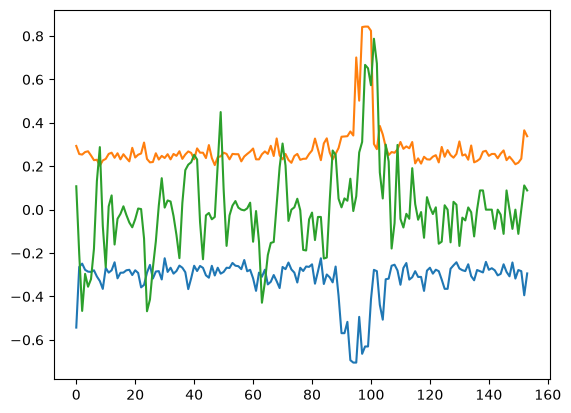

In [36]:
plt.plot(cog_delta_eagles_low[:154])
plt.plot(cog_delta_eagles_high[:154])
plt.plot(eagles_y[:154, 0])

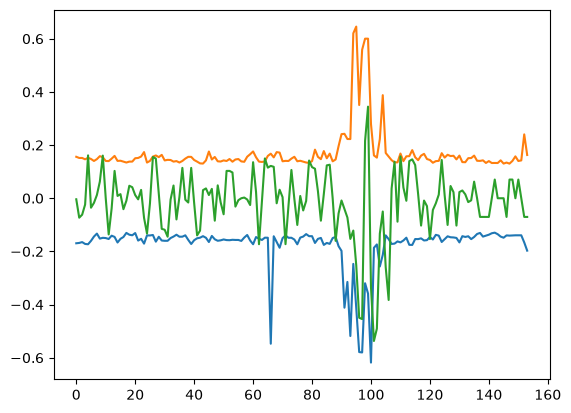

In [37]:
plt.plot(delta_dif_eagles_low[:154])
plt.plot(delta_dif_eagles_high[:154])
plt.plot(eagles_y[:154, 1])

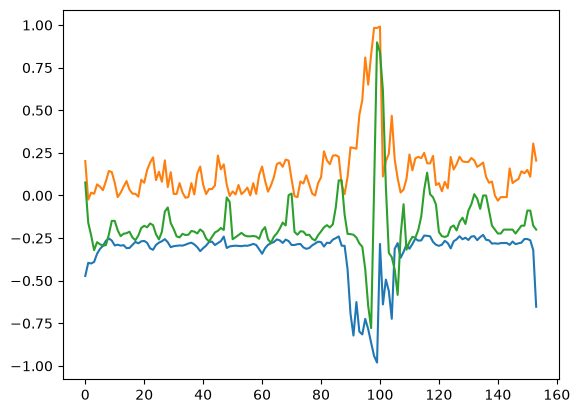

In [38]:
plt.plot(dif_eagles_low[:154])
plt.plot(dif_eagles_high[:154])
plt.plot(eagles_y[:154, 2])

In [39]:
import time
time.sleep(120)

KeyboardInterrupt: 

In [ ]:
np.mean( (
    (dif_eagles_low < eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 2]) &
    (dif_eagles_high > eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 2])
) )

np.float64(0.8968609865470852)

In [ ]:
import time
time.sleep(120)

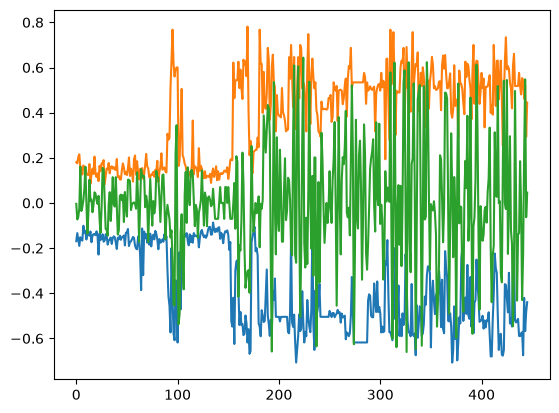

In [ ]:
plt.plot(delta_dif_eagles_low)
plt.plot(delta_dif_eagles_high)
plt.plot(eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 1])

In [ ]:
np.mean( (
    (delta_dif_eagles_low < eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 1]) &
    (delta_dif_eagles_high > eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 1])
) )

np.float64(0.8946188340807175)

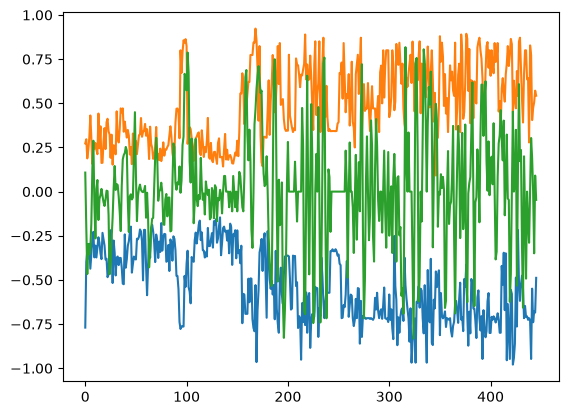

In [ ]:
plt.plot(cog_delta_eagles_low)
plt.plot(cog_delta_eagles_high)
plt.plot(eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 0])

In [ ]:
np.mean( (
    (cog_delta_eagles_low < eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 0]) &
    (cog_delta_eagles_high > eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 0])
) )

np.float64(0.8856502242152466)

In [ ]:
vezhen_model_out = qrf_best.predict(vezhen_x, quantiles=[0.025, 0.975])
vezhen_low, vezhen_high = vezhen_model_out[:, :, 0], vezhen_model_out[:, :, 1]

In [ ]:
vezhen_low = vezhen_low.reshape((vezhen_low.shape[0], 5, 3))
vezhen_high = vezhen_high.reshape((vezhen_high.shape[0], 5, 3))

cog_delta_vezhen_low = vezhen_low[:, 0, 0]
cog_delta_vezhen_high = vezhen_high[:, 0, 0]

delta_dif_vezhen_low = vezhen_low[:, 0, 1]
delta_dif_vezhen_high = vezhen_high[:, 0, 1]

dif_vezhen_low = vezhen_low[:, 0, 2]
dif_vezhen_high = vezhen_high[:, 0, 2]

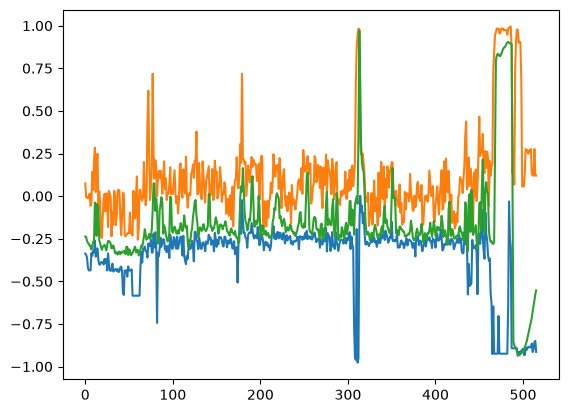

In [ ]:
plt.plot(dif_vezhen_low)
plt.plot(dif_vezhen_high)
plt.plot(vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 2])

In [ ]:
np.mean( (
    (dif_vezhen_low < vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 2]) &
    (dif_vezhen_high > vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 2])
) )

np.float64(0.9457364341085271)

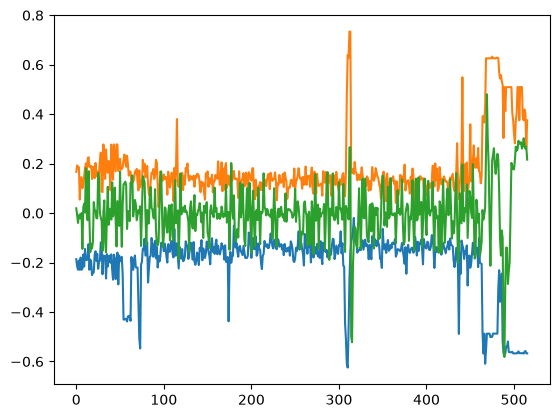

In [ ]:
plt.plot(delta_dif_vezhen_low)
plt.plot(delta_dif_vezhen_high)
plt.plot(vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 1])

In [ ]:
np.mean( (
    (delta_dif_vezhen_low < vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 1]) &
    (delta_dif_vezhen_high > vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 1])
) )

np.float64(0.9302325581395349)

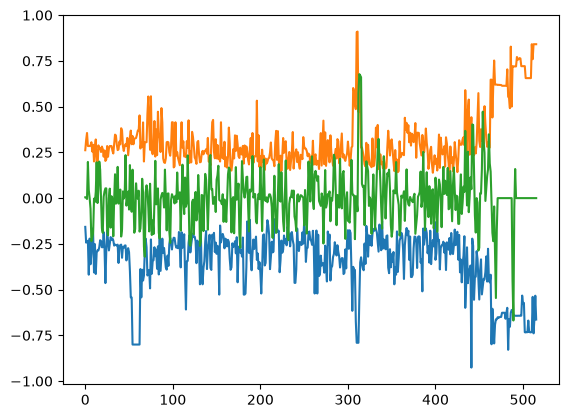

In [ ]:
plt.plot(cog_delta_vezhen_low)
plt.plot(cog_delta_vezhen_high)
plt.plot(vezhen_y[:, 0])

In [ ]:
np.mean( (
    (cog_delta_vezhen_low < vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 0]) &
    (cog_delta_vezhen_high > vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 0])
) )

np.float64(0.939922480620155)

# Base model with only selected features

In [ ]:
with open('../../output/models/qrf/qrf-featcounts-loss.pkl', 'rb+') as f:
    feat_counts = pickle.load(f)
with open('../../output/models/qrf/qrf-remove-features.pkl', 'rb+') as f:
    rm_feats = pickle.load(f)

In [ ]:
import seaborn as sns

Text(0, 0.5, 'Loss')

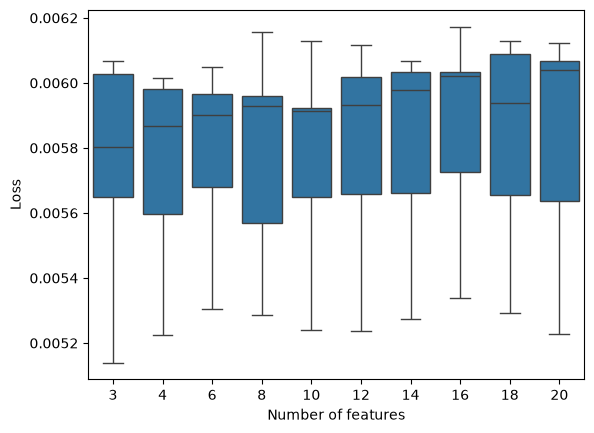

In [ ]:
df_featcounts_loss = pd.DataFrame(feat_counts).melt()

df_featcounts_loss['variable'] = 20-df_featcounts_loss['variable']

sns.boxplot(
    data=df_featcounts_loss,
    x='variable',
    y='value'
)

plt.xlabel('Number of features')
plt.ylabel('Loss')

In [ ]:
df = pd.read_csv('../../output/data_eagles_vezhen/df-prepared-eagle.csv')
df.drop(columns=['day', 'MMSI']).columns

Index(['SPEED', 'COURSE', 'currentSpeed', 'gust', 'swellHeight', 'waveHeight',
       'windSpeed', 'dif', 'COURSE_vec_x', 'COURSE_vec_y',
       'currentDirection_vec_x', 'currentDirection_vec_y',
       'swellDirection_vec_x', 'swellDirection_vec_y', 'waveDirection_vec_x',
       'waveDirection_vec_y', 'windDirection_vec_x', 'windDirection_vec_y',
       'COURSE-dif', 'delta_dif'],
      dtype='object')

In [ ]:
rm_feats

[np.int64(6),
 np.int64(3),
 np.int64(2),
 np.int64(5),
 np.int64(4),
 np.int64(14),
 np.int64(1),
 np.int64(15),
 np.int64(13),
 np.int64(12),
 np.int64(11),
 np.int64(17),
 np.int64(0),
 np.int64(16),
 np.int64(10),
 np.int64(8),
 np.int64(9),
 np.int64(19)]

In [ ]:
X_train_sel = X_train\
    .reshape((-1, 5, 20))\
    [:, :, [7, 18, 19]]\
    .reshape((-1, 5*3))

qrf_best = RandomForestQuantileRegressor(**best_params)\
    .fit(X_train_sel, y_train)

In [ ]:
vezhen_x_sel = vezhen_x\
    .reshape((-1, 5, 20))\
    [:, :, [7, 18, 19]]\
    .reshape((-1, 5*3))

vezhen_model_out = qrf_best.predict(vezhen_x_sel, quantiles=[0.025, 0.975])
vezhen_low, vezhen_high = vezhen_model_out[:, :, 0], vezhen_model_out[:, :, 1]

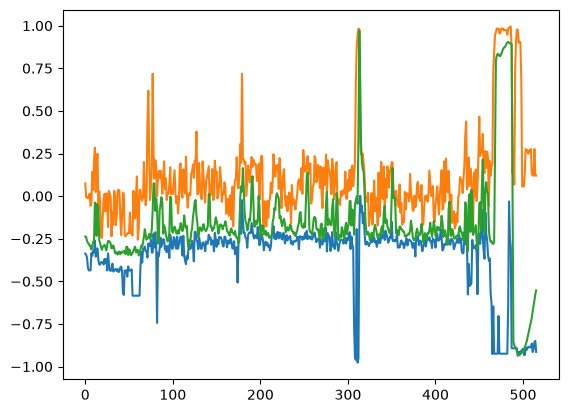

In [ ]:
plt.plot(dif_vezhen_low)
plt.plot(dif_vezhen_high)
plt.plot(vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 2])

In [ ]:
np.mean( (
    (dif_vezhen_low < vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 2]) &
    (dif_vezhen_high > vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 2])
) )

np.float64(0.9457364341085271)

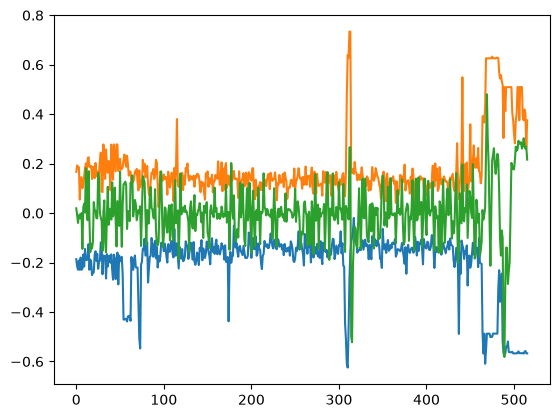

In [ ]:
plt.plot(delta_dif_vezhen_low)
plt.plot(delta_dif_vezhen_high)
plt.plot(vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 1])

In [ ]:
np.mean( (
    (delta_dif_vezhen_low < vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 1]) &
    (delta_dif_vezhen_high > vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 1])
) )

np.float64(0.9302325581395349)

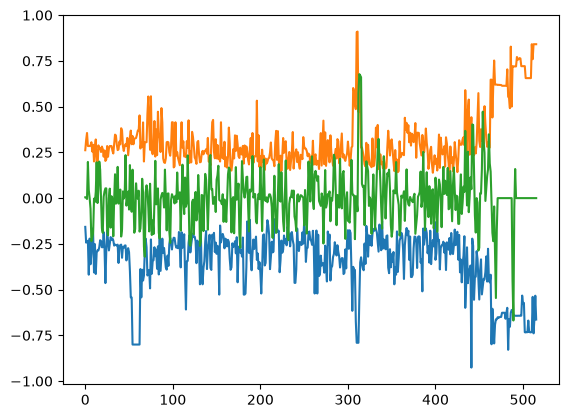

In [ ]:
plt.plot(cog_delta_vezhen_low)
plt.plot(cog_delta_vezhen_high)
plt.plot(vezhen_y[:, 0])

In [ ]:
np.mean( (
    (cog_delta_vezhen_low < vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 0]) &
    (cog_delta_vezhen_high > vezhen_y.reshape(vezhen_y.shape[0], 5, 3)[:, 0, 0])
) )

np.float64(0.939922480620155)

In [ ]:
eagles_x = eagles_x\
    .reshape((-1, 5, 20))\
    [:, :, [7, 18, 19]]\
    .reshape((-1, 5*3))

eagles_model_out = qrf_best.predict(eagles_x, quantiles=[0.025, 0.975])
eagles_low, eagles_high = eagles_model_out[:, :, 0], eagles_model_out[:, :, 1]

In [ ]:
eagles_low = eagles_low.reshape((eagles_low.shape[0], 5, 3))
eagles_high = eagles_high.reshape((eagles_high.shape[0], 5, 3))

cog_delta_eagles_low = eagles_low[:, 0, 0]
cog_delta_eagles_high = eagles_high[:, 0, 0]

delta_dif_eagles_low = eagles_low[:, 0, 1]
delta_dif_eagles_high = eagles_high[:, 0, 1]

dif_eagles_low = eagles_low[:, 0, 2]
dif_eagles_high = eagles_high[:, 0, 2]

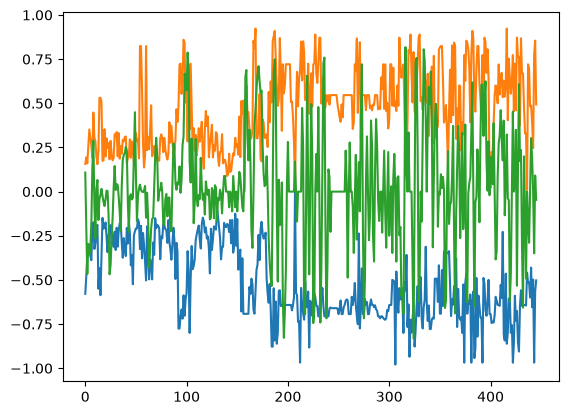

In [ ]:
plt.plot(cog_delta_eagles_low)
plt.plot(cog_delta_eagles_high)
plt.plot(eagles_y[:, 0])

In [ ]:
np.mean( (
    (cog_delta_eagles_low < eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 0]) &
    (cog_delta_eagles_high > eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 0])
) )

np.float64(0.8542600896860987)

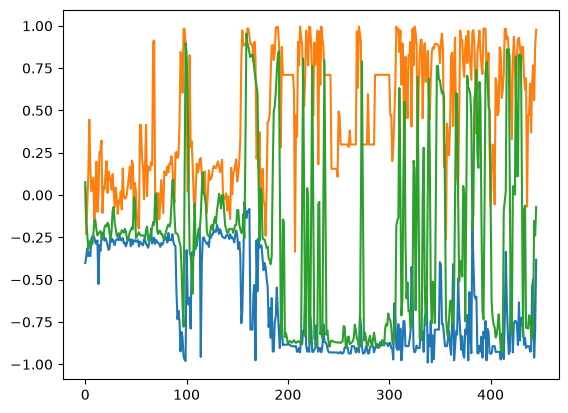

In [ ]:
plt.plot(dif_eagles_low)
plt.plot(dif_eagles_high)
plt.plot(eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 2])

In [ ]:
np.mean( (
    (dif_eagles_low < eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 2]) &
    (dif_eagles_high > eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 2])
) )

np.float64(0.820627802690583)

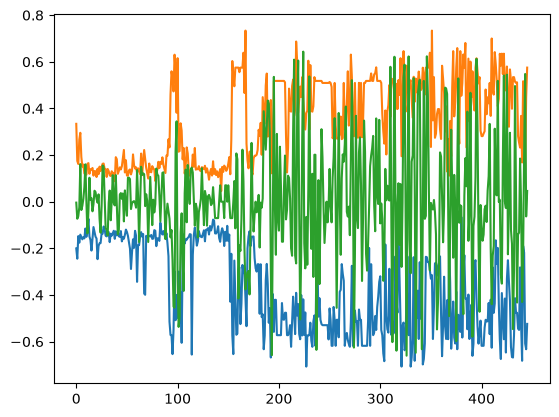

In [ ]:
plt.plot(delta_dif_eagles_low)
plt.plot(delta_dif_eagles_high)
plt.plot(eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 1])

In [ ]:
np.mean( (
    (delta_dif_eagles_low < eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 1]) &
    (delta_dif_eagles_high > eagles_y.reshape(eagles_y.shape[0], 5, 3)[:, 0, 1])
) )

np.float64(0.8677130044843049)